# 🤖 المختبر السادس: التنبؤ بالفعالية بالتعلم الآلي

**الفصل الحادي عشر من الكتاب — من الاستعلام إلى التنبؤ**

---

في المختبرات السابقة **حسبنا** (حركية، PK/PD) و**فرزنا** (ليبنسكي، ADME) و**استعلمنا** (قواعد البيانات). اليوم ننتقل للقفزة الأخيرة: **نموذج يتعلم من قياسات مخبرية حقيقية ثم يتنبأ بفعالية جزيئات لم يرها قط**.

**الرحلة في هذا الدفتر:**
1. تحميل قياسات IC50 **حقيقية** لهدف SARS-CoV-2 Mpro من ChEMBL (نفس القاعدة التي تخدم شركات الأدوية)
2. تحويل الجزيئات إلى أرقام تفهمها الخوارزميات: **بصمات Morgan**
3. تدريب **Random Forest** وتقييمه بصدق (R² و RMSE على بيانات لم يرها)
4. التنبؤ لأدوية معتمدة حقيقية — مع **فترة ثقة** تكشف حدود النموذج

> **لماذا هذا مهم؟** تجربة IC50 واحدة قد تستغرق أسابيع في المختبر. نموذج جيد يتنبأ بآلاف الجزيئات في ثوانٍ — فلترة أولية توجّه المختبر نحو المرشحين الواعدين فقط.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

RDLogger.DisableLog("rdApp.*")          # إسكات سجلات RDKit الإنشائية
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
rng_seed = 42

print("✅ البيئة جاهزة")

✅ البيئة جاهزة


## 📚 النظرية (1): لماذا pIC50 وليس IC50؟

القياس الخام $IC_{50}$ هو التركيز الذي يمنع 50% من نشاط الإنزيم. مشكلته أن **سلمه غير متماثل**:
- مثبط ممتاز: IC50 = 10 nM
- مثبط ضعيف: IC50 = 10,000 nM (10 µM)

الفارق ألف ضعف! لكن لو حوّلنا للسلم اللوغاريتمي **pIC50**:

$$pIC_{50} = -\log_{10}(IC_{50}[M])$$

- 10 nM → pIC50 = **9.0**
- 10 µM → pIC50 = **5.0**

الآن الفارق = 4 وحدات على سلم مضغوط متماثل — وهذا ما تحتاجه الانحدارات.

> **ChEMBL يوفر هذا مباشرة**: عمود `pchembl_value` محسوب مسبقاً من القياسات المنحنية (curve-fitted) — لذلك سنستخدمه.

In [2]:
# البيانات المرفقة: 900 جزيء — وسيط pchembl لكل جزيء، نظيفة من قياسات
# data_validity_comment، أحادية المكون، متحقق منها بـ RDKit.
# المصدر الكامل: CHEMBL4523582 (Mpro) — standard_type=IC50, units=nM.

DATA = Path("data/mpro_sample.csv")
if not DATA.exists():
    # لو شغّلت الدفتر من مكان آخر — اضبط المسار يدوياً
    DATA = Path.cwd() / "data" / "mpro_sample.csv"

df = pd.read_csv(DATA)
print(f"الجزيئات: {len(df)}")
print(f"pIC50 → min: {df.pchembl_value.min():.2f} | median: {df.pchembl_value.median():.2f} | max: {df.pchembl_value.max():.2f}")
df.head(3)

الجزيئات: 900
pIC50 → min: 4.01 | median: 5.97 | max: 9.45


,smiles,pchembl_value,mol_chembl_id
0,Cn1cnc(Cn2c(=O)[nH]/c(=N\c3cc4cn(C)nc4cc3Cl)n(...,9.45,CHEMBL5183847
1,O=C(NCc1cccs1)[C@@H]1CN(C(=O)c2cc(=O)[nH]c(=O)...,9.40,CHEMBL5204987
2,O=C(NCc1ccco1)C1CN(C(=O)c2cc(=O)[nH]c(=O)[nH]2...,9.23,CHEMBL5181886


**للتذكير — كيف حُمّلت هذه البيانات؟** عبر ChEMBL REST:
```
activity.json?target_chembl_id=CHEMBL4523582&standard_type=IC50
&standard_units=nM&standard_relation==
```
نفس مهارة المختبر الرابع — هنا نحولها من استعلام إلى **نموذج تنبؤ**.

## 🔍 استكشاف البيانات

قبل أي نموذج: ما شكل التوزيع؟ وهل هناك علاقة ظاهرية بين الحجم الجزيئي والفعالية؟

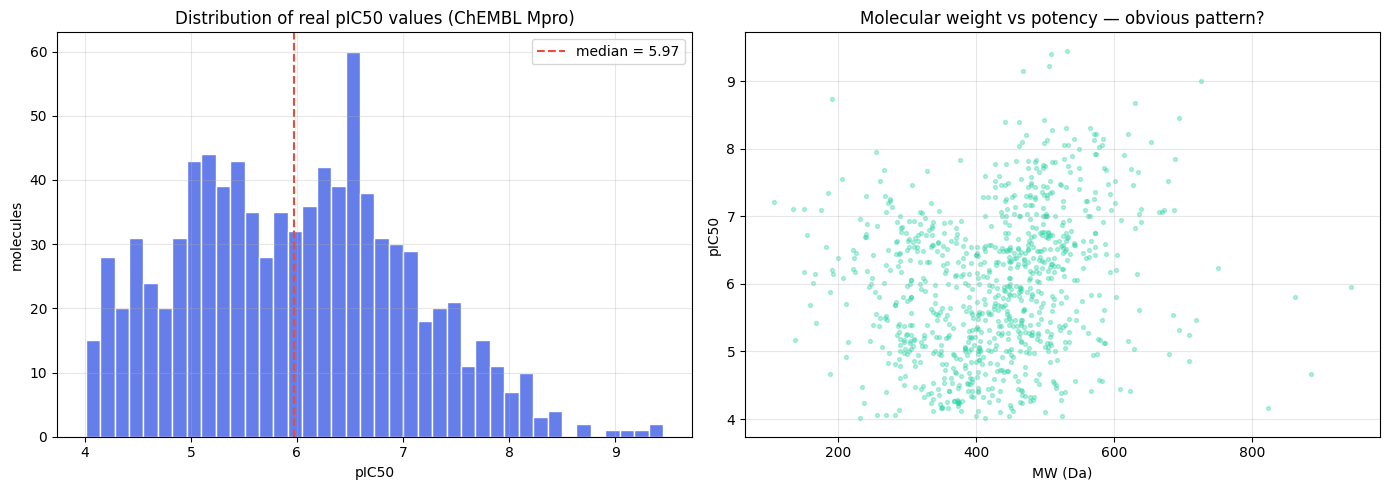

مدى pIC50 = 5.44 وحدات — نطاق فعلي واسع


In [3]:
df["molwt"] = [Descriptors.MolWt(Chem.MolFromSmiles(s)) for s in df.smiles]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df.pchembl_value, bins=40, color="#667eea", edgecolor="white")
axes[0].axvline(df.pchembl_value.median(), color="#e74c3c", ls="--",
                label=f"median = {df.pchembl_value.median():.2f}")
axes[0].set_title("Distribution of real pIC50 values (ChEMBL Mpro)")
axes[0].set_xlabel("pIC50"); axes[0].set_ylabel("molecules"); axes[0].legend()

axes[1].scatter(df.molwt, df.pchembl_value, s=8, alpha=0.35, color="#2dd4a7")
axes[1].set_title("Molecular weight vs potency — obvious pattern?")
axes[1].set_xlabel("MW (Da)"); axes[1].set_ylabel("pIC50")
plt.tight_layout(); plt.show()

print(f"مدى pIC50 = {df.pchembl_value.max()-df.pchembl_value.min():.2f} وحدات — نطاق فعلي واسع")

> **ملاحظة الفارما الناقد:** لا توجد علاقة قوية MW↔الفعالية (النشرة اليمنى مشتتة). لو كانت موجودة لكفى الحجم وحده نموذجاً! الحقيقة أن **الفعالية تُقاس بالبنية الفراغية ثلاثية الأبعاد** — وهنا يأتي دور البصمات.

## 🧬 النظرية (2): بصمات Morgan — كيف يرى النموذج الجزيء؟

النموذج لا يفهم SMILES نصاً. نحوّل كل جزيء إلى **متجه ثنائي بطول 2048 بت**:
- لكل ذرة، نستخرج **كل البيئات الدائرية** حتى نصف قطر 2 رابطة
- كل بيئة فريدة تُسقط (hash) على بت في المتجه وتُشعل
- جزيئان متشابهان يشعلان بتات متقاربة → تصبح **التشابه الكيميائي قرباً هندسياً**

هذا هو الخط الرابط بين الكيمياء وعلم البيانات — وميزة إضافية: **النموذج قابل للتفسير جزئياً** (أي البتات التي أشعلها الجزء النشط؟).

In [4]:
FPGEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def morgan_fp(smiles: str):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return None
    fp = FPGEN.GetFingerprint(m)
    arr = np.zeros((2048,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

X_all, valid_idx = [], []
for i, s in enumerate(df.smiles):
    fp = morgan_fp(s)
    if fp is not None:
        X_all.append(fp); valid_idx.append(i)

X_all = np.array(X_all)
y_all = df.pchembl_value.values[valid_idx]

on_bits = X_all[0].sum()
print(f"مصفوفة البصمات: {X_all.shape} (جزيئات × بتات)")
print(f"مثال: أول جزيء يشعل {on_bits} بتاً من 2048 ({on_bits/2048:.1%}) — التخلخل طبيعي ومقصود")

مصفوفة البصمات: (900, 2048) (جزيئات × بتات)
مثال: أول جزيء يشعل 63 بتاً من 2048 (3.1%) — التخلخل طبيعي ومقصود


## 🎯 التدريب والانقسام الأمين

**Random Forest**: غابة من 300 شجرة انحدار، كل شجرة تتعلم من عينة عشوائية من الجزيئات والبتات، والتنبؤ النهائي = متوسط الأشجار.

**القاعدة الذهبية**: نحتفظ بـ 20% من الجزيئات **لا يراها النموذج أبداً** (test set) — تقييمها هو درجة الصدق الوحيدة. نثبت `random_state=42` ليتكرر الجميع النتيجة نفسها.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.2, random_state=rng_seed
)

model = RandomForestRegressor(
    n_estimators=300, random_state=rng_seed, n_jobs=-1
)
model.fit(X_tr, y_tr)

pred = model.predict(X_te)
r2 = model.score(X_te, y_te)
rmse = float(np.sqrt(np.mean((y_te - pred) ** 2)))
mae = float(np.mean(np.abs(y_te - pred)))

print(f"تدريب: {len(X_tr)} | اختبار: {len(X_te)}")
print(f"R²   = {r2:.3f}   (0=عشوائي، 1=كامل — للبيانات الحقيقية: 0.3-0.6 جيد بميزات بسيطة)")
print(f"RMSE = {rmse:.3f} وحدة pIC50  (خطأ نموذجي ≈ عامل {10**rmse:.1f}× في IC50)")
print(f"MAE  = {mae:.3f}")

تدريب: 720 | اختبار: 180
R²   = 0.436   (0=عشوائي، 1=كامل — للبيانات الحقيقية: 0.3-0.6 جيد بميزات بسيطة)
RMSE = 0.776 وحدة pIC50  (خطأ نموذجي ≈ عامل 6.0× في IC50)
MAE  = 0.571


> **اقرأ RMSE بدواء**: RMSE ≈ 0.78 يعني خطأ نموذجياً بحجم عامل ≈ 6× في IC50. قد يبدو كبيراً — لكن لتجربة تخول مئات الجزيئات، هذا كافٍ لترتيب المرشحين وتوفير **80%+ من التجارب**. دقة أعلى تحتاج بصمات ثلاثية الأبعاد أو نماذج عصبية (DeepChem — المشروع القادم!).

## 📊 التنبؤ مقابل الواقع — أهم رسم في الدفتر

كل نقطة = جزيء لم يره النموذج. الخط المتقطع = التنبؤ المثالي (y=x).
**كيف تقرأه:** نقاط قرب الخط = نجاح | نقاط أعلى/أسفل الخط = خطأ النموذج | تشتت متوازن = نموذج أمين بلا انحياز منهجي.

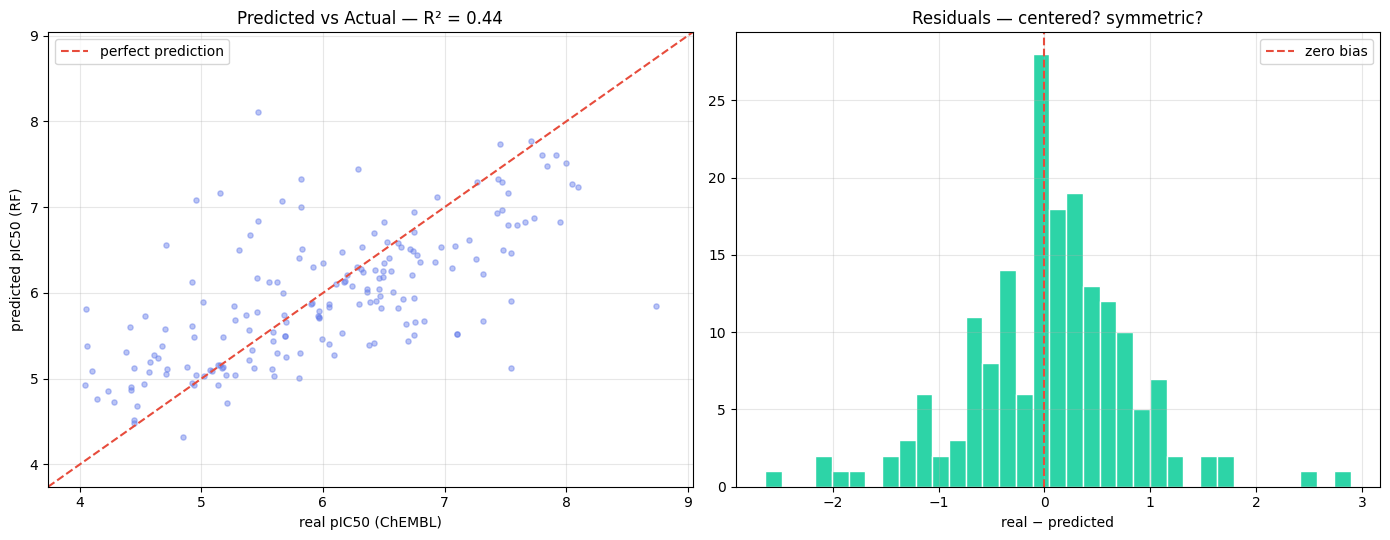

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

lo, hi = min(y_te.min(), pred.min()) - 0.3, max(y_te.max(), pred.max()) + 0.3
axes[0].scatter(y_te, pred, s=14, alpha=0.45, color="#667eea")
axes[0].plot([lo, hi], [lo, hi], "--", color="#e74c3c", lw=1.5, label="perfect prediction")
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_xlabel("real pIC50 (ChEMBL)"); axes[0].set_ylabel("predicted pIC50 (RF)")
axes[0].set_title(f"Predicted vs Actual — R² = {r2:.2f}"); axes[0].legend()

residuals = y_te - pred
axes[1].hist(residuals, bins=35, color="#2dd4a7", edgecolor="white")
axes[1].axvline(0, color="#e74c3c", ls="--", label="zero bias")
axes[1].set_title("Residuals — centered? symmetric?")
axes[1].set_xlabel("real − predicted"); axes[1].legend()

plt.tight_layout(); plt.show()

## 🎚️ النظرية (3): فترة الثقة — النموذج يعترف بحدوده

كل شجرة تنبئ بقيمة؛ **تباين تنبؤات الأشجار = مقياس عدم يقين**:
- أشجار متفقة (σ صغير) → الجزيء **يشبه جزيئات التدريب** → ثقة
- أشجار متفرقة (σ كبير) → الجزيء **غريب عن كل ما تعلمه** → فترة عريضة

هذا "عدم يقين إبيستيمي" عملي — وبلا تعقيد رياضي إضافي. جرّبه على أدوية حقيقية:

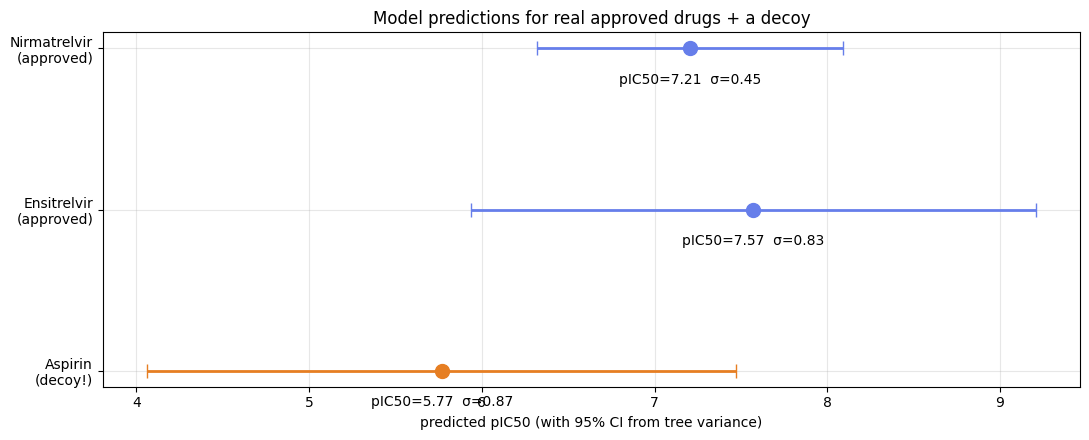

Nirmatrelvir   pIC50=7.21 (CI 6.32–8.09) ≈ IC50 62 nM
Ensitrelvir    pIC50=7.57 (CI 5.94–9.21) ≈ IC50 27 nM
Aspirin        pIC50=5.77 (CI 4.06–7.47) ≈ IC50 1,706 nM


In [7]:
NIRMATRELVIR = "CC1([C@@H]2[C@H]1[C@H](N(C2)C(=O)[C@H](C(C)(C)C)NC(=O)C(F)(F)F)C(=O)N[C@@H](C[C@@H]3CCNC3=O)C#N)C"
ENSITRELVIR  = "CN1C=C2C=C(C(=CC2=N1)Cl)NC3=NC(=O)N(C(=O)N3CC4=CC(=C(C=C4F)F)F)CC5=NN(C=N5)C"
ASPIRIN      = "CC(=O)OC1=CC=CC=C1C(=O)O"

def predict_with_ci(model, smiles: str) -> dict:
    fp = morgan_fp(smiles)
    fp2 = fp.reshape(1, -1)
    tree_preds = np.array([t.predict(fp2)[0] for t in model.estimators_])
    mean, std = tree_preds.mean(), tree_preds.std()
    return {"pic50": mean, "std": std, "ci": (mean - 1.96*std, mean + 1.96*std)}

labels = ["Nirmatrelvir\n(approved)", "Ensitrelvir\n(approved)", "Aspirin\n(decoy!)"]
results = [predict_with_ci(model, s) for s in (NIRMATRELVIR, ENSITRELVIR, ASPIRIN)]

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (lab, r) in enumerate(zip(labels, results)):
    color = "#667eea" if i < 2 else "#e67e22"
    xerr = np.array([[r["pic50"] - r["ci"][0]], [r["ci"][1] - r["pic50"]]])  # (2,1)
    ax.errorbar(r["pic50"], i, xerr=xerr,
                fmt="o", ms=10, color=color, ecolor=color, capsize=5, lw=2)
    ax.text(r["pic50"], i + 0.22,
            f"pIC50={r['pic50']:.2f}  σ={r['std']:.2f}", ha="center", fontsize=10)
ax.set_yticks(range(3)); ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("predicted pIC50 (with 95% CI from tree variance)")
ax.set_title("Model predictions for real approved drugs + a decoy")
plt.tight_layout(); plt.show()

for lab, r in zip(labels, results):
    ic50_nm = 10 ** (-r["pic50"]) * 1e9
    print(f"{lab.splitlines()[0]:<14} pIC50={r['pic50']:.2f} (CI {r['ci'][0]:.2f}–{r['ci'][1]:.2f}) ≈ IC50 {ic50_nm:,.0f} nM")

**لماذا فترة الأسبرين أوسع بكثير؟** لأن الأسبرين لا يشبه أي جزيء في مجموعة تدريب Mpro — الأشجار "تخمّن" من مناطق مختلفة من معرفتها. **النموذج يعترف بجهله** — وهذه أهم فضيلة في النمذجة الدوائية المسؤولة.

*(القيم الأدبية المرجعية: نيرماتريلڤير IC50 ≈ 19 nM → pIC50 ≈ 7.7، إنستريلفير ≈ 7.9 nM → ≈ 8.1 — جرّب وقارن!)*

## ✍️ تمارين (حل ذاتي التحقق)

**تمرين 1:** هل النتيجة مستقرة؟ أعد التدريب بـ `n_estimators=30` — هل يتغير R² كثيراً؟
**تمرين 2:** خذ دواء تعرفه (اكتب SMILES من PubChem كم في المختبر الرابع) وتنبأ له.
**تمرين 3:** متى **لا** تثق بالنموذج؟ اطبع الجزيئات التي σ فيها > 1.0 من مجموعة الاختبار.

In [8]:
# ── تمرين 1: استقرار النتيجة ──
model_small = RandomForestRegressor(n_estimators=30, random_state=rng_seed, n_jobs=-1)
model_small.fit(X_tr, y_tr)
r2_small = model_small.score(X_te, y_te)
print(f"R² بـ 30 شجرة: {r2_small:.3f} مقابل {r2:.3f} بـ 300 — الفارق {(abs(r2-r2_small)/r2):.1%} فقط")
assert abs(r2 - r2_small) < 0.1, "الفرق كبير — تحقق من البذور!"

# ── تمرين 3: متى لا نثق؟ ──
tree_matrix = np.array([t.predict(X_te) for t in model.estimators_])  # (trees, n_test)
sigmas = tree_matrix.std(axis=0)
uncertain = (sigmas > 1.0).sum()
print(f"\nجزيئات اختبار بـ σ > 1.0: {uncertain} من {len(sigmas)} ({uncertain/len(sigmas):.0%})")
assert len(sigmas) == len(y_te)

print("\n✅ كل التمارين نجحت")

R² بـ 30 شجرة: 0.436 مقابل 0.436 بـ 300 — الفارق 0.1% فقط

جزيئات اختبار بـ σ > 1.0: 9 من 180 (5%)

✅ كل التمارين نجحت


## 🧭 خلاصة المختبر السادس

| المفهوم | ما تعلمناه |
|---|---|
| pIC50 | سلم لوغاريتمي متماثل يجعل الانحدار ممكناً |
| بصمات Morgan | ترجمة البنية الكيميائية إلى متجه رقمي 2048 بت |
| Random Forest | 300 شجرة — قوي بلا ضبط معقد، ويفسَّر جزئياً |
| التقييم الأمين | R²/RMSE على جزيئات لم يرها النموذج أبداً |
| فترة الثقة | تباين الأشجار = "أعرف ما لا أعرف" |

**الخطوة القادمة — Capstone**: نربط كل المختبرات في خط واحد مؤتمت: هدف دوائي → فرز → تنبؤ بالفعالية → PK/PD → تقرير قرار.